In [1]:
# import packages
import sys
import time
from pathlib import Path

import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from jaxley_ephys import detect_spikes, spike_features, sweep_features

# # set float to 64 (matches Allen exactly; float32 is within about 1e-4)
# jax.config.update("jax_enable_x64", True)

# set up paths / constants
REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
DATA = REPO / "tests" / "testdata" / "allen_cache"  # see tests/load_testdata.py
SPECIMEN_ID = 519832676
KINDS = ("short_square", "long_square", "ramp")
sys.path.insert(0, str(REPO))  # for the Allen data loader of the tests

sweeps: {'short_square': [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25], 'long_square': [26, 30, 31, 32, 33, 34, 35, 37, 38, 39, 40, 41, 42, 43], 'ramp': [4, 5, 6]}
spiking sweeps: {'short_square': [20, 21, 22, 23, 24, 25], 'long_square': [38, 39, 40, 41, 42, 43], 'ramp': [4, 5, 6]}


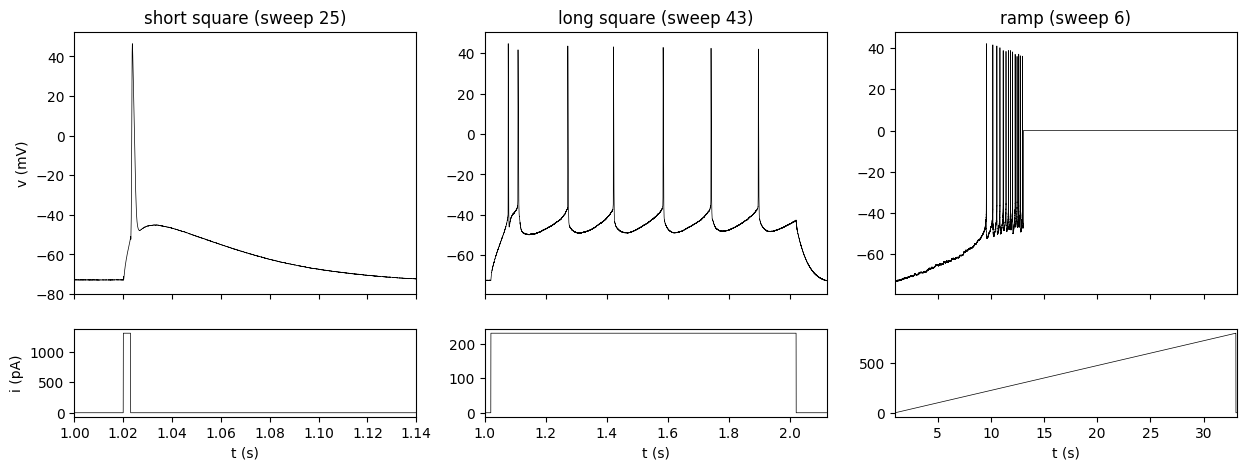

In [2]:
# load allen specimen
from tests.utils.allen_dataset import load_specimen_case  # reads NWB with AllenSDK

case = load_specimen_case(SPECIMEN_ID, data_root=str(DATA))
sweeps = {kind: [r.sweep_number for r in case.records(kind=kind)] for kind in KINDS}
spiking = {
    kind: [r.sweep_number for r in case.records(kind=kind, has_spikes=True)]
    for kind in KINDS
}
print("sweeps:", sweeps)
print("spiking sweeps:", spiking)

# plot data (3 subplots: short square, long square, and ramp)
fig, axes = plt.subplots(2, 3, figsize=(15, 5), sharex="col", height_ratios=(3, 1))
for col, kind in enumerate(KINDS):
    # t (s), v (mV), i (pA) and the stimulus window [start, end] (s)
    t, v, i, start, end = case.trace_for(spiking[kind][-1])
    axes[0, col].plot(t, v, "k", lw=0.5)
    axes[1, col].plot(t, i, "k", lw=0.5)
    axes[0, col].set_title(f"{kind.replace('_', ' ')} (sweep {spiking[kind][-1]})")
    axes[1, col].set_xlim(start - 0.02, max(end, start + 0.02) + 0.1)
    axes[1, col].set_xlabel("t (s)")
axes[0, 0].set_ylabel("v (mV)")
axes[1, 0].set_ylabel("i (pA)")
plt.show()

7 spikes


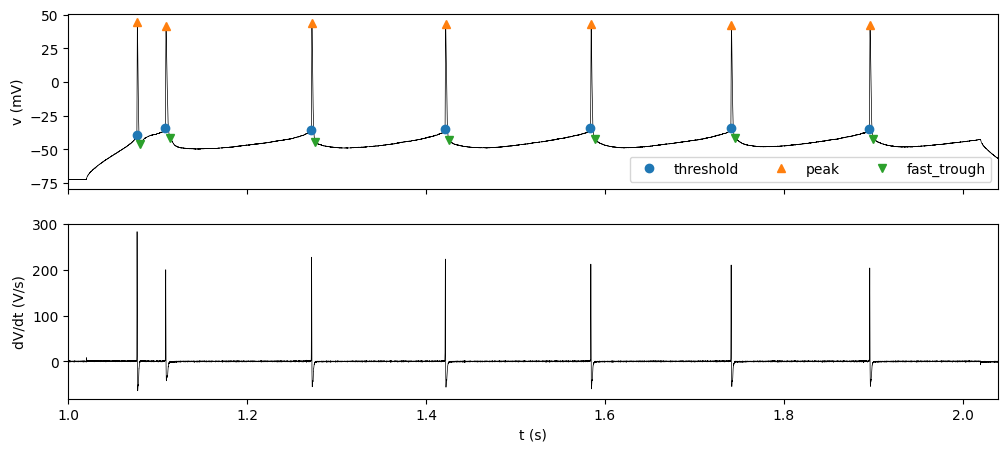

In [3]:
# compute events and visualize them for long square
t, v, i, start, end = case.trace_for(spiking["long_square"][-1])
sp = detect_spikes(t, v, i, start, end)  # Allen's default parameters
n = int(sp.n_spikes)  # per-spike buffers hold max_spikes entries, valid up to n
print(f"{n} spikes")

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, v, "k", lw=0.5)
for name, marker in [("threshold", "o"), ("peak", "^"), ("fast_trough", "v")]:
    idx = np.asarray(getattr(sp, name))[:n]
    idx = idx[idx >= 0]  # -1 where a spike has no such point
    axes[0].plot(t[idx], v[idx], marker, label=name)
axes[0].legend(ncol=3, loc="lower right")
axes[0].set_ylabel("v (mV)")
# Bessel-filtered (10 kHz) dV/dt; NaN after t_cutoff (by default 20 ms after the
# window): later samples cannot affect any feature and are not analysed
axes[1].plot(t, sp.dvdt, "k", lw=0.5)
axes[1].set(xlim=(start - 0.02, end + 0.02), xlabel="t (s)", ylabel="dV/dt (V/s)")
plt.show()

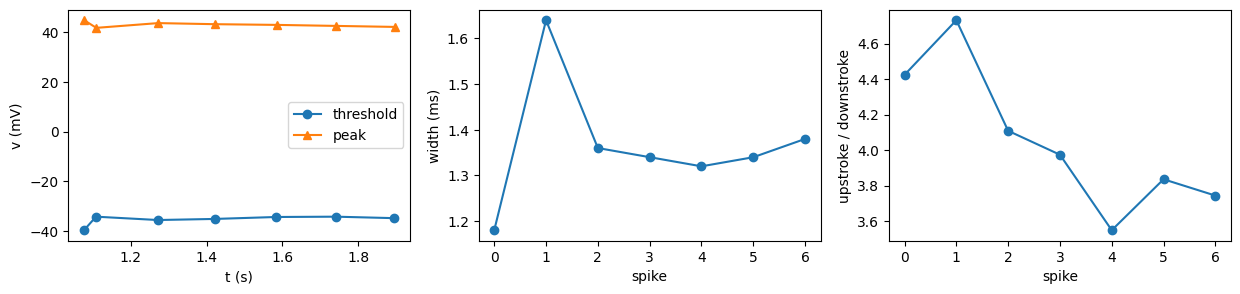

,threshold_t,threshold_v,peak_v,fast_trough_v,width,clipped
0,1.07650,-39.593754,44.718754,-45.937500,0.00118,False
1,1.10842,-34.156250,41.656254,-41.468750,0.00164,False
2,1.27158,-35.500000,43.562500,-44.562504,0.00136,False
3,1.42114,-35.062504,43.125004,-43.437504,0.00134,False
4,1.58382,-34.281250,42.843750,-42.500000,0.00132,False
5,1.74072,-34.156250,42.437500,-41.875000,0.00134,False
6,1.89572,-34.750004,42.031250,-42.031250,0.00138,False


In [4]:
# compute spike features and visualize them for long square
# The columns of Allen's spike table; times in s, voltages in mV, dV/dt in V/s.
spikes = pd.DataFrame({k: np.asarray(x)[:n] for k, x in spike_features(sp).items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].plot(spikes["threshold_t"], spikes["threshold_v"], "o-", label="threshold")
axes[0].plot(spikes["peak_t"], spikes["peak_v"], "^-", label="peak")
axes[0].set(xlabel="t (s)", ylabel="v (mV)")
axes[0].legend()
axes[1].plot(1e3 * spikes["width"], "o-")
axes[1].set(xlabel="spike", ylabel="width (ms)")
axes[2].plot(spikes["upstroke_downstroke_ratio"], "o-")
axes[2].set(xlabel="spike", ylabel="upstroke / downstroke")
plt.show()
spikes[["threshold_t", "threshold_v", "peak_v", "fast_trough_v", "width", "clipped"]]

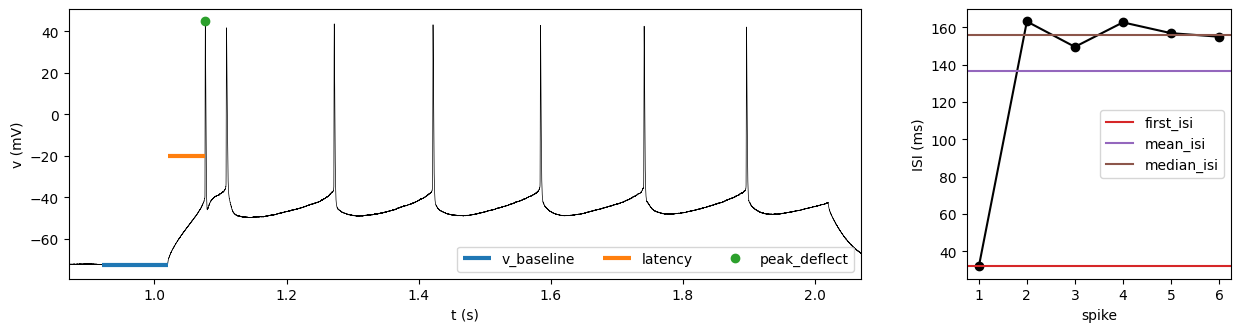

adapt                     0.129420
avg_rate                  7.000140
first_isi                31.919956
isi_cv                    0.344335
latency                   0.056500
mean_isi                136.536652
median_isi              155.950012
min_deflect             -72.468750
min_deflect_i           230.000000
peak_deflect             44.718754
peak_deflect_index    53855.000000
sag                            NaN
stim_amp                230.000000
tau                            NaN
v_baseline              -72.451042
dtype: float64

In [5]:
# compute sweep features and visualize them for long square
features = sweep_features(sp, stimulus="long_square")  # stim_amp as for long squares

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5), width_ratios=(3, 1))
axes[0].plot(t, v, "k", lw=0.5)
baseline, latency = features["v_baseline"], features["latency"]
axes[0].hlines(baseline, start - 0.1, start, "C0", lw=3, label="v_baseline")
axes[0].hlines(-20, start, start + latency, "C1", lw=3, label="latency")
deflect_t = t[features["peak_deflect_index"]]
axes[0].plot(deflect_t, features["peak_deflect"], "C2o", label="peak_deflect")
axes[0].set(xlim=(start - 0.15, end + 0.05), xlabel="t (s)", ylabel="v (mV)")
axes[0].legend(ncol=3, loc="lower right")
isis = 1e3 * np.diff(spikes["threshold_t"])  # ms, like the ISI features
axes[1].plot(np.arange(1, n), isis, "ko-")
for k, name in enumerate(["first_isi", "mean_isi", "median_isi"]):
    axes[1].axhline(features[name], color=f"C{k + 3}", label=name)
axes[1].set(xlabel="spike", ylabel="ISI (ms)")
axes[1].legend()
plt.show()
pd.Series({k: float(x) for k, x in features.items()})  # ISIs and tau in ms

In [6]:
# demonstrate jit for reuse on a different sweep for long square
# detect_spikes, spike_features and sweep_features are compiled on their first call
# for each input shape (and dtype, filter, max_spikes); later calls reuse the code.
jax.clear_caches()  # forget the code compiled above, to show the first-call cost
for number in spiking["long_square"][:4]:
    t_k, v_k, i_k, start_k, end_k = case.trace_for(number)
    tic = time.perf_counter()
    sp_k = detect_spikes(t_k, v_k, i_k, start_k, end_k)
    rate = sweep_features(sp_k, stimulus="long_square")["avg_rate"]
    jax.block_until_ready(rate)
    ms = 1e3 * (time.perf_counter() - tic)
    print(f"sweep {number}: {float(rate):.0f} Hz in {ms:.0f} ms")

sweep 38: 1 Hz in 4654 ms
sweep 39: 3 Hz in 44 ms
sweep 40: 4 Hz in 43 ms
sweep 41: 5 Hz in 39 ms


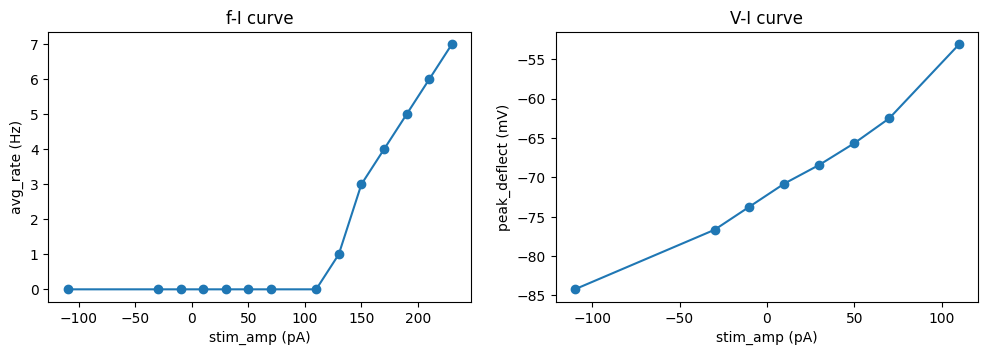

,adapt,avg_rate,first_isi,isi_cv,latency,mean_isi,median_isi,min_deflect,min_deflect_i,peak_deflect,peak_deflect_index,sag,stim_amp,tau,v_baseline
26,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-84.218758,-110.000000,-84.218758,56361,0.160721,-110.000000,20.760090,-74.661697
30,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-76.656250,-29.999998,-76.656250,60036,0.119593,-29.999998,29.600035,-73.239449
31,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-73.718758,-10.000000,-73.718758,100860,0.315830,-10.000000,70.546104,-72.098824
32,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-72.875000,10.000000,-70.781250,63153,NaN,10.000000,NaN,-72.840782
33,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-72.593758,29.999998,-68.406258,57797,NaN,29.999998,NaN,-72.520264
34,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-72.281258,50.000000,-65.656250,61663,NaN,50.000000,NaN,-72.314812
35,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-72.406258,70.000000,-62.500000,61828,NaN,70.000000,NaN,-72.230820
37,NaN,0.00000,NaN,NaN,NaN,NaN,NaN,-72.406258,110.000000,-53.093754,66032,NaN,110.000000,NaN,-72.419418
38,NaN,1.00002,NaN,NaN,0.17478,NaN,NaN,-72.406258,130.000000,45.531250,59770,NaN,130.000000,NaN,-72.362434
39,0.298882,3.00006,244.080063,0.298882,0.10578,348.129974,348.129974,-71.718750,150.000000,45.000000,56319,NaN,150.000000,NaN,-71.657425


In [7]:
# use vmap to compute sweep features for long square
# All long squares of this cell have the same length, so they can be batched.
traces = [case.trace_for(number) for number in sweeps["long_square"]]
t_s, v_s, i_s = (np.stack([trace[k] for trace in traces]) for k in range(3))  # [S, T]
start_s, end_s = (np.array([trace[k] for trace in traces]) for k in (3, 4))  # [S]


@jax.jit
@jax.vmap
def analyse(t, v, i, start, end):
    sp = detect_spikes(t, v, i, start, end)
    return sp.overflow, sweep_features(sp, stimulus="long_square")


overflow, batch = analyse(t_s, v_s, i_s, start_s, end_s)
assert not overflow.any()  # no error can be raised inside jit/vmap

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(batch["stim_amp"], batch["avg_rate"], "o-")
axes[0].set(xlabel="stim_amp (pA)", ylabel="avg_rate (Hz)", title="f-I curve")
subthreshold = batch["avg_rate"] == 0
axes[1].plot(batch["stim_amp"][subthreshold], batch["peak_deflect"][subthreshold], "o-")
axes[1].set(xlabel="stim_amp (pA)", ylabel="peak_deflect (mV)", title="V-I curve")
plt.show()
pd.DataFrame({k: np.asarray(x) for k, x in batch.items()}, index=sweeps["long_square"])

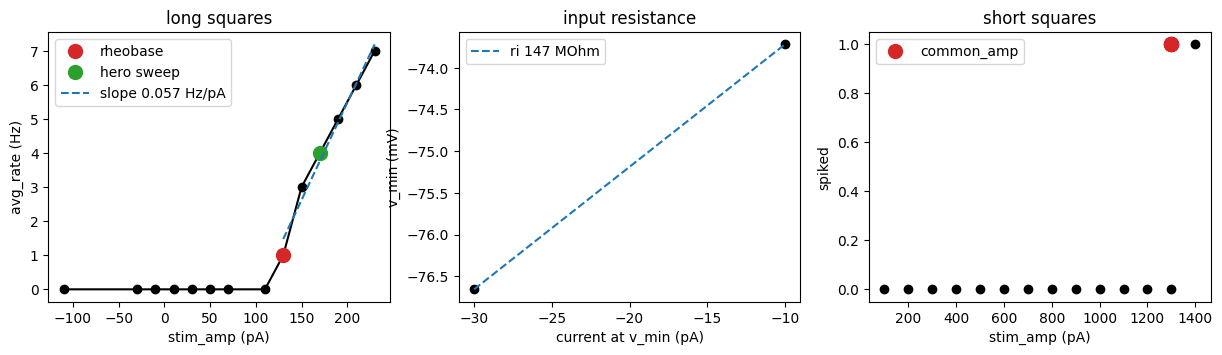

short squares: dv_cutoff 12.6 V/s, thresh_frac 0.10
spiking ramps: [4, 5, 6]


In [8]:
# compute sweepset features and visualize them for long square, short square, ramp
from jaxley_ephys import extract_cell_features, long_square_features
from jaxley_ephys.cell import LONG_SQUARE_WINDOW, RAMP_START


def sweep_list(kind, window=None):
    """(t, v, i, start, end) of all sweeps of one stimulus type. Like Allen, analyse
    from the stimulus onset to the end of the sweep (end=None) unless a window is
    given: a short-square spike comes after the 3 ms pulse."""
    out = []
    for number in sweeps[kind]:
        t_k, v_k, i_k, start_k, _ = case.trace_for(number)
        out.append((t_k, v_k, i_k, *(window or (start_k, None))))
    return out


# Spikes -> sweep features -> sweepset features -> cell features for all sweeps.
# Short-square spikes are detected with Allen's adjusted dv_cutoff / thresh_frac.
cell = extract_cell_features(
    sweep_list("long_square", LONG_SQUARE_WINDOW),  # Allen's windows
    sweep_list("short_square"),
    sweep_list("ramp", (RAMP_START, None)),
)
ls, ss, ramps = cell["long_squares"], cell["short_squares"], cell["ramps"]

# The sweepset functions only need the stacked [S] sweep and first-spike features:
same = long_square_features(ls["sweeps"], ls["first_spikes"])
assert np.isclose(same["fi_fit_slope"], ls["fi_fit_slope"])

amp, rate = ls["sweeps"]["stim_amp"], ls["sweeps"]["avg_rate"]
rheo, hero = int(ls["rheobase_index"]), int(ls["hero_index"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(amp, rate, "ko-")
axes[0].plot(amp[rheo], rate[rheo], "C3o", ms=10, label="rheobase")
axes[0].plot(amp[hero], rate[hero], "C2o", ms=10, label="hero sweep")
spk = np.asarray(ls["spiking"])
fit = rate[spk].mean() + ls["fi_fit_slope"] * (amp[spk] - amp[spk].mean())
axes[0].plot(
    amp[spk], fit, "C0--", label=f"slope {float(ls['fi_fit_slope']):.3f} Hz/pA"
)
axes[0].set(xlabel="stim_amp (pA)", ylabel="avg_rate (Hz)", title="long squares")
axes[0].legend()

mem = np.asarray(ls["membrane_property"])
i_min, v_min = ls["sweeps"]["min_deflect_i"][mem], ls["sweeps"]["min_deflect"][mem]
axes[1].plot(i_min, v_min, "ko")
line = v_min.mean() + 1e-3 * ls["input_resistance"] * (i_min - i_min.mean())
axes[1].plot(i_min, line, "C0--", label=f"ri {float(ls['input_resistance']):.0f} MOhm")
axes[1].set(
    xlabel="current at v_min (pA)", ylabel="v_min (mV)", title="input resistance"
)
axes[1].legend()

ss_amp, common = ss["sweeps"]["stim_amp"], np.asarray(ss["common_amp"])
axes[2].plot(ss_amp, ss["sweeps"]["avg_rate"] > 0, "ko")
axes[2].plot(ss_amp[common], np.ones(common.sum()), "C3o", ms=10, label="common_amp")
axes[2].set(xlabel="stim_amp (pA)", ylabel="spiked", title="short squares")
axes[2].legend()
plt.show()
print(
    f"short squares: dv_cutoff {float(ss['dv_cutoff']):.1f} V/s, "
    f"thresh_frac {float(ss['thresh_frac']):.2f}"
)
print(f"spiking ramps: {[n for n, s in zip(sweeps['ramp'], ramps['spiking']) if s]}")

In [9]:
# show cell features: the Allen Cell Types Database features, next to the DB values
def db_value(name):
    try:
        return float(case.feature_row[name])
    except (KeyError, ValueError):
        return np.nan


# The DB follows a few extra conventions (allen_ephys/ALLEN_EPHYS_FIXES.md, section 4):
# e.g. threshold_i_short_square is the pulse amplitude in the DB, while Allen's code
# averages the current at threshold, which is 0 for spikes starting after the pulse.
# In float32 (x64 off above), a few values differ from the DB by up to ~1e-3.
pd.DataFrame(
    {
        "jaxley_ephys": {k: float(x) for k, x in cell["cell"].items()},
        "allen_db": {k: db_value(k) for k in cell["cell"]},
    }
)

,jaxley_ephys,allen_db
adaptation,0.179194,0.179194
avg_isi,245.906662,245.906667
latency,0.086620,0.086620
f_i_curve_slope,0.057143,0.057143
ri,146.874619,146.874636
sag,0.160723,0.160742
tau,50.052200,50.049031
vm_for_sag,-84.218758,-84.218758
vrest,-72.547661,-72.547661
fast_trough_t_long_square,1.198760,1.198760
